In [1]:
#Get the imports
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models

In [2]:
#The Radio data
V1535_radio = pd.read_csv('v1535_Sco_Radio.txt', delim_whitespace = True, header = 0)

freq = V1535_radio['Freq(Ghz)']
flux = V1535_radio['FluxDensity(mJy)']
err = V1535_radio['Uncertainty(mJy)']
day = V1535_radio['Day']

/var/folders/xv/dvsld6lx4xs_nbgh_qcl11d00000gn/T/ipykernel_17319/3637782763.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  V1535_radio = pd.read_csv('v1535_Sco_Radio.txt', delim_whitespace = True, header = 0)


In [3]:
#Sort data by freq and non detections 

A = np.logical_and(freq>= 0, freq<= 1.5) 
L_AC = np.where(np.logical_and(A, flux > 3*err)) 
L_nac = np.where(np.logical_and(A, flux < 3*err))

freq_LAC = np.ravel([freq[i] for i in L_AC])
flux_LAC = np.ravel([flux[i] for i in L_AC])
err_LAC  = np.ravel([err[i] for i in L_AC])
date_LAC = np.ravel([day[i] for i in L_AC])

nflux_LAC = np.ravel([flux[i] + err[i]*3 for i in L_nac])
ndate_LAC = np.ravel([day[i] for i in L_nac])


###############################################################
B = np.logical_and(freq>= 1.5, freq<= 2)
L_BD = np.where(np.logical_and(B, flux > 3*err)) 
L_nbd = np.where(np.logical_and(B, flux < 3*err))

freq_LBD = np.ravel([freq[i] for i in L_BD])
flux_LBD = np.ravel([flux[i] for i in L_BD])
err_LBD  = np.ravel([err[i] for i in L_BD])
date_LBD = np.ravel([day[i] for i in L_BD])

nflux_LBD = np.ravel([flux[i] + err[i]*3 for i in L_nbd])
ndate_LBD = np.ravel([day[i] for i in L_nbd])


###############################################################
C = np.logical_and(freq>= 3, freq<= 5)
C_AC = np.where(np.logical_and(C, flux > 3*err)) 
C_nac = np.where(np.logical_and(C, flux < 3*err))

freq_CAC = np.ravel([freq[i] for i in C_AC])
flux_CAC = np.ravel([flux[i] for i in C_AC])
err_CAC  = np.ravel([err[i] for i in C_AC])
date_CAC = np.ravel([day[i] for i in C_AC])

nflux_CAC = np.ravel([flux[i] + err[i]*3 for i in C_nac])
ndate_CAC = np.ravel([day[i] for i in C_nac])


###############################################################
D = np.logical_and(freq>= 5, freq<= 8) 
C_BD = np.where(np.logical_and(D, flux > 3*err)) 
C_nbd = np.where(np.logical_and(D, flux < 3*err))

freq_CBD = np.ravel([freq[i] for i in C_BD])
flux_CBD = np.ravel([flux[i] for i in C_BD])
err_CBD  = np.ravel([err[i] for i in C_BD])
date_CBD = np.ravel([day[i] for i in C_BD])

nflux_CBD = np.ravel([flux[i] + err[i]*3 for i in C_nbd])
ndate_CBD = np.ravel([day[i] for i in C_nbd])

###############################################################
E = np.logical_and(freq>= 10, freq<= 14)
Ku_AC =  np.where(np.logical_and(E, flux > 3*err))  
Ku_nac = np.where(np.logical_and(E, flux < 3*err))  

freq_K_AC = np.ravel([freq[i] for i in Ku_AC])
flux_K_AC = np.ravel([flux[i] for i in Ku_AC])
err_K_AC  = np.ravel([err[i] for i in Ku_AC])
date_K_AC = np.ravel([day[i] for i in Ku_AC])

nflux_K_AC = np.ravel([flux[i] + err[i]*3 for i in Ku_nac])
ndate_K_AC = np.ravel([day[i] for i in Ku_nac])
###############################################################
F = np.logical_and(freq>= 15, freq<= 20)
Ku_BD =  np.where(np.logical_and(F, flux > 3*err))  
Ku_nbd = np.where(np.logical_and(F, flux < 3*err))  

freq_K_BD = np.ravel([freq[i] for i in Ku_BD])
flux_K_BD = np.ravel([flux[i] for i in Ku_BD])
err_K_BD  = np.ravel([err[i] for i in Ku_BD])
date_K_BD = np.ravel([day[i] for i in Ku_BD])

nflux_K_BD = np.ravel([flux[i] + err[i]*3 for i in Ku_nbd])
ndate_K_BD = np.ravel([day[i] for i in Ku_nbd])
###############################################################

G = np.logical_and(freq>= 21, freq<= 30)
Ka_AC =  np.where(np.logical_and(G, flux > 3*err)) 
Ka_nac = np.where(np.logical_and(G, flux < 3*err)) 

freq_Ka_AC = np.ravel([freq[i] for i in Ka_AC])
flux_Ka_AC = np.ravel([flux[i] for i in Ka_AC])
err_Ka_AC  = np.ravel([err[i] for i in Ka_AC])
date_Ka_AC = np.ravel([day[i] for i in Ka_AC])

nflux_Ka_AC = np.ravel([flux[i] + err[i]*3 for i in Ka_nac])
ndate_Ka_AC = np.ravel([day[i] for i in Ka_nac])
###############################################################

H = np.logical_and(freq>= 31, freq<= 40)
Ka_BD =  np.where(np.logical_and(H, flux > 3*err))  
Ka_nbd = np.where(np.logical_and(H, flux < 3*err))

freq_Ka_BD = np.ravel([freq[i] for i in Ka_BD])
flux_Ka_BD = np.ravel([flux[i] for i in Ka_BD])
err_Ka_BD  = np.ravel([err[i] for i in Ka_BD])
date_Ka_BD = np.ravel([day[i] for i in Ka_BD])

nflux_Ka_BD = np.ravel([flux[i] + err[i]*3 for i in Ka_nbd])
ndate_Ka_BD = np.ravel([day[i] for i in Ka_nbd])

In [4]:
def quad(err,freq,flux):
    quad_er = []

    for i in range(len(freq)):
        if freq[i] < 10.0:
            p1 = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            quad_er.append(p1)
           
        
        else: 
            p2 = np.sqrt(err[i]**2 + (flux[i]*0.10)**2)
            quad_er.append(p2)
            
        
    return(quad_er)  

In [5]:
#Error in Quadrature

quad_Lac = quad(err_LAC,freq_LAC, flux_LAC)  
quad_Lbd = quad(err_LBD,freq_LBD, flux_LBD)   
quad_Cac = quad(err_CAC,freq_CAC, flux_CAC)
quad_Cbd = quad(err_CBD,freq_CBD, flux_CBD)
quad_Kac = quad(err_K_AC,freq_K_AC, flux_K_AC)
quad_Kbd = quad(err_K_BD,freq_K_BD, flux_K_BD)
quad_Kaac = quad(err_Ka_AC,freq_Ka_AC, flux_Ka_AC)
quad_Kabd = quad(err_Ka_BD,freq_Ka_BD, flux_Ka_BD)


# Now for the optical data 

In [6]:
#optical data input

V1535Sco_opt_unflitered = pd.read_csv('v1535sco.txt', header = 0)

#now to get only the vband

column_name = 'Band'
key = 'V'

V1535_opt_kinda = V1535Sco_opt_unflitered[V1535Sco_opt_unflitered[column_name].str.contains(key, na=False)]

V1535_opt = V1535_opt_kinda[~V1535_opt_kinda[column_name].str.contains('Vis.|CV', na=False)]

V1535_opt

,JD,Magnitude,Uncertainty,HQuncertainty,Band,Observer Code,Comment Code(s),Comp Star 1,Comp Star 2,Charts,...,Cmag,Kmag,HJD,Star Name,Observer Affiliation,Measurement Method,Grouping Method,ADS Reference,Digitizer,Credit
5,2.457067e+06,9.498,0.0200,NaN,V,WRCA,NaN,ENSEMBLE,105,14400EOK,...,NaN,10.4970,NaN,PNV J17032620-3504140,AAVSO,STD,NaN,NaN,NaN,NaN
6,2.457067e+06,9.517,0.0270,NaN,V,WRCA,NaN,ENSEMBLE,105,14400EOK,...,NaN,10.4920,NaN,PNV J17032620-3504140,AAVSO,STD,NaN,NaN,NaN,NaN
9,2.457069e+06,9.9640,0.0095,NaN,V,SPET,NaN,127,134,14431OX,...,13.5531,14.2749,NaN,PNV J17032620-3504140,AAVSO,STD,NaN,NaN,NaN,NaN
10,2.457069e+06,9.9534,0.0097,NaN,V,SPET,NaN,127,134,14431OX,...,13.5605,14.2809,NaN,PNV J17032620-3504140,AAVSO,STD,NaN,NaN,NaN,NaN
11,2.457069e+06,9.9567,0.0095,NaN,V,SPET,NaN,127,134,14431OX,...,13.5565,14.2747,NaN,PNV J17032620-3504140,AAVSO,STD,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5317,2.457279e+06,15.284,0.0410,NaN,V,SPET,NaN,127,134,14441KJ,...,13.2070,13.9660,NaN,NOVA SCO 2015,AAVSO,STD,NaN,NaN,NaN,NaN
5321,2.457280e+06,15.40,0.0800,NaN,V,NLX,NaN,Ensemble,129,14452BSJ,...,NaN,12.9000,NaN,V1535 Sco,AAVSO,STD,NaN,NaN,NaN,NaN
5324,2.457282e+06,15.216,0.0390,NaN,V,SPET,NaN,127,134,14441KJ,...,13.1910,13.9260,NaN,NOVA SCO 2015,AAVSO,STD,NaN,NaN,NaN,NaN
5328,2.457283e+06,14.871,0.0380,NaN,V,SPET,NaN,127,134,14441KJ,...,13.2000,13.9320,NaN,NOVA SCO 2015,AAVSO,STD,NaN,NaN,NaN,NaN


In [7]:
#JD = 2457065.81389
#JD t_0 = 2457064.5000000

opticaldays = ((V1535_opt['JD'].astype(float)) - 2457064.5000000)
vmag = V1535_opt['Magnitude'].astype(float)
error_vmag = V1535_opt['Uncertainty'].astype(float)

In [8]:
alpha = [-0.89, -0.56, 0.87, -0.29, 0.98, 0.34, 0.18, -0.28, -0.24, -0.15, -0.06]

alpha_err = [0.03, 0.07,0.05, 0.28, 0.07, 0.18, 0.04, 0.07, 0.03, 0.09, 0.84]

alpha_day = [2.7, 7.2, 12.7, 17.7, 23.7, 26.6, 41.6, 55.15, 66.0, 78.5, 93.5]

# Now both together

In [9]:
vmag

5        9.4980
6        9.5170
9        9.9640
10       9.9534
11       9.9567
         ...   
5317    15.2840
5321    15.4000
5324    15.2160
5328    14.8710
5332    15.2360
Name: Magnitude, Length: 256, dtype: float64

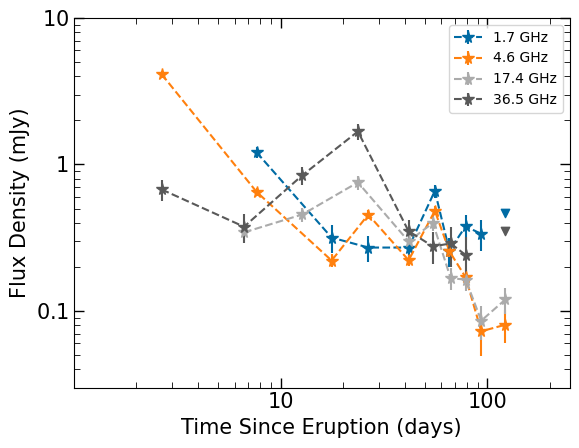

In [9]:
plt.style.use('tableau-colorblind10')

from matplotlib.ticker import AutoMinorLocator
#now the radio
plt.ylabel('Flux Density (mJy)',fontsize=15)
plt.xlabel('Time Since Eruption (days)',fontsize=15)

plt.xscale('log')
plt.yscale('log')



plt.errorbar(date_LBD, flux_LBD, yerr=quad_Lbd, linestyle ='--', fmt = '*' , markersize = 8.5, label='1.7 GHz')
plt.errorbar(date_CAC, flux_CAC, yerr=quad_Cac, linestyle ='--', fmt = '*', markersize = 8.5, label='4.6 GHz')
plt.errorbar(date_K_BD, flux_K_BD, yerr=quad_Kbd, linestyle ='--', fmt = '*', markersize = 8.5 , label='17.4 GHz')
plt.errorbar(date_Ka_BD, flux_Ka_BD, yerr=quad_Kabd, linestyle ='--', fmt = '*' , markersize = 8.5, label='36.5 GHz')


plt.scatter(ndate_LBD, nflux_LBD, marker = 'v')
plt.scatter(ndate_CAC, nflux_CAC, marker = 'v')
plt.scatter(ndate_K_BD, nflux_K_BD , marker = 'v')
plt.scatter(ndate_Ka_BD, nflux_Ka_BD , marker = 'v')


plt.legend()
plt.yticks([0.1,1.0,10], labels = [r'$0.1$',r'$1$',r'$10$'], fontsize = 15)
plt.ylim(0.03,10)
plt.xlim(1,250)
plt.xticks([10,100], labels = ['10','100'], fontsize = 15)

plt.tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
plt.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

plt.savefig("V1535Sco_justradio.png")


plt.show()


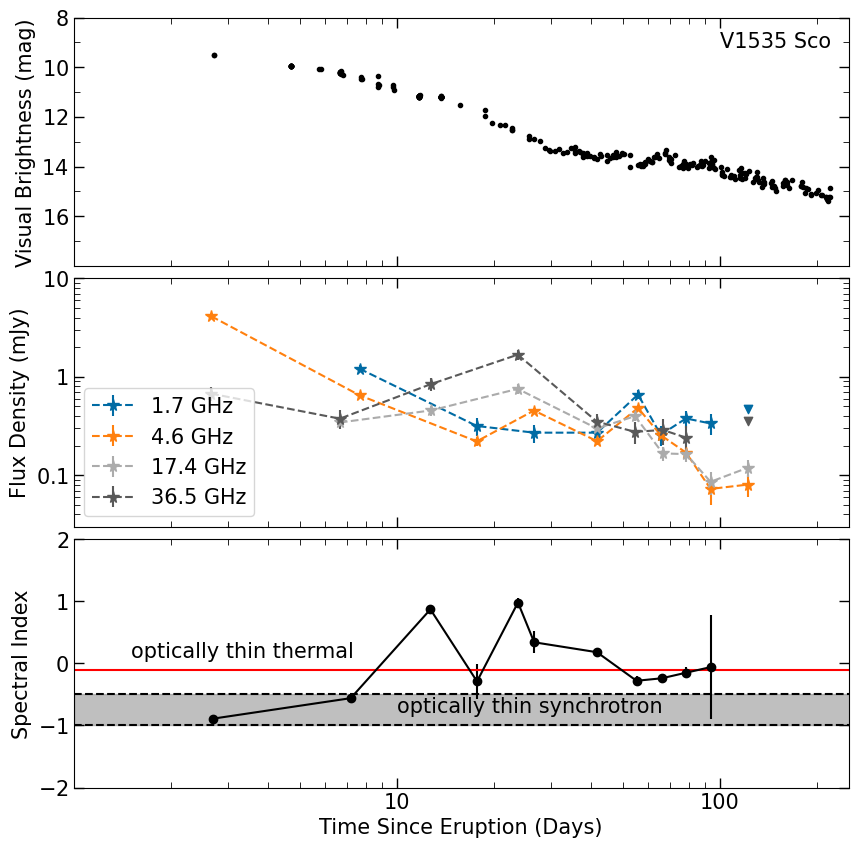

In [10]:
plt.style.use('tableau-colorblind10')

from matplotlib.ticker import AutoMinorLocator

fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharey=False, sharex = True)#, constrained_layout=True)


#first the visual
axs[0].scatter(opticaldays, vmag, marker = '.', color = 'black')
axs[0].annotate('V1535 Sco',(100,9.2), fontsize=15)

axs[0].set_xscale('log')
#axs[0].set_yscale('log')

axs[0].set_ylabel('Visual Brightness (mag)',fontsize =15)

axs[0].set_yticks([8,10,12,14,16], labels = [r'$8$',r'$10$', r'$12$', r'$14$',r'$16$'], fontsize = 15)
axs[0].set_ylim(8,18)
axs[0].invert_yaxis()
axs[0].tick_params(which='minor', length=4, direction = 'in', top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[0].yaxis.set_minor_locator(AutoMinorLocator(2))  # 2 minor intervals between major ticks
axs[0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)


#now the radio
axs[1].set_ylabel('Flux Density (mJy)',fontsize=15)
axs[1].set_xscale('log')
axs[1].set_yscale('log')



axs[1].errorbar(date_LBD, flux_LBD, yerr=quad_Lbd, linestyle ='--', fmt = '*' , markersize = 8.5, label='1.7 GHz')
axs[1].errorbar(date_CAC, flux_CAC, yerr=quad_Cac, linestyle ='--', fmt = '*', markersize = 8.5, label='4.6 GHz')
#axs[1].errorbar(date_CBD, flux_CBD, yerr=quad_Cbd, linestyle ='--', fmt = '*', markersize = 8.5 , label='7.4 Ghz')
axs[1].errorbar(date_K_BD, flux_K_BD, yerr=quad_Kbd, linestyle ='--', fmt = '*', markersize = 8.5 , label='17.4 GHz')
axs[1].errorbar(date_Ka_BD, flux_Ka_BD, yerr=quad_Kabd, linestyle ='--', fmt = '*' , markersize = 8.5, label='36.5 GHz')


axs[1].scatter(ndate_LBD, nflux_LBD, marker = 'v')
axs[1].scatter(ndate_CAC, nflux_CAC, marker = 'v')
#axs[1].scatter(ndate_CBD, nflux_CBD, marker = 'v')
axs[1].scatter(ndate_K_BD, nflux_K_BD , marker = 'v')
axs[1].scatter(ndate_Ka_BD, nflux_Ka_BD , marker = 'v')


axs[1].legend(fontsize=15, loc='lower left')

axs[1].set_yticks([0.1,1.0,10], labels = [r'$0.1$',r'$1$',r'$10$'], fontsize = 15)
axs[1].set_ylim(0.03,10)

axs[1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)


########### Panel 3 ############

axs[2].errorbar(alpha_day, alpha, yerr=alpha_err, marker = 'o', color = 'black')
axs[2].axhline(y = -0.1, color = 'red', linestyle = '-')
axs[2].axhline(y = -0.5, color = 'black', linestyle = '--')
axs[2].axhline(y = -1, color = 'black', linestyle = '--')
axs[2].fill_between(x=[1,300],y1=-0.5,y2=-1, color = 'grey', alpha=.5)

axs[2].set_xlabel('Time Since Eruption (Days)', fontsize=15)
axs[2].set_ylabel('Spectral Index', fontsize=15)
axs[2].annotate('optically thin thermal', (1.5,0.1), fontsize=15)
axs[2].annotate('optically thin synchrotron', (10,-0.8), fontsize=15)

axs[2].set_xticks([10,100], labels = ['10','100'], fontsize = 15)
axs[2].set_yticks([-2,-1,0,1,2], labels = [r'$-2$',r'$-1$',r'$0$',r'$1$',r'$2$'], fontsize = 15)
axs[2].set_ylim(-2,2)
axs[2].set_xlim(1,250)

axs[2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)



fig.subplots_adjust(hspace=0.05)
plt.savefig("V1535Sco_RadioOptical_lightcurves.png")
plt.show();